# Chấm GA-ECBM và ECBM gốc trên CUB, seed 2026 (không train lại)

> **Lượt chấm (13/11/2026)**, giống cách `ga-ecbm-cub-test` chấm seed 42. Notebook này là `ga-ecbm-cub-seed2026` với `SCORE_ONLY = True`: mục 12 thấy checkpoint GA-ECBM đủ 100 epoch ở Input nên bỏ qua train, rồi chấm cả hai mô hình bằng cùng một code.
>
> **Input (bắt buộc):** Output của `ga-ecbm-cub-seed2026`, Output của `ecbm-cub-seed2026`, dataset ảnh CUB (`wenewone/cub2002011`). Thiếu hoặc gắn nhầm seed thì mục 2 báo lỗi ngay, trước khi tốn GPU.
>
> **Tập test:** `EVALUATE_TEST = True` — user đồng ý chấm test CUB seed 123 và 2026 ngày 13/11/2026. Chấm validation và test cho cả hai mô hình, khoảng 3.2 giờ.

> **Bản thêm seed (13/11/2026).** Giống hệt notebook `ga-ecbm-cub` (seed 42). **Chỉ khác:** `random_seed = 2026`; precision cố định 16 như seed 42; kiểm tra checkpoint ECBM ở Input đúng seed 2026. Chấm test sau: chạy lại chính notebook này với `EVALUATE_TEST = True` và Input là Output của lần chạy này (mục 12 thấy checkpoint đủ 100 epoch nên bỏ qua train), giống cách đã làm ở `ga-ecbm-cub-test`.

Notebook này dựng trên notebook tái lập `ECBM_CUB` (code gốc xmed-lab/ECBM, commit `d38c43a`). **Mọi thứ giữ nguyên** như lần tái lập: dữ liệu CUB của CBM, ResNet101 ảnh 299, nhánh ảnh → nhãn E_class và nhánh ảnh → concept E_concept của tác giả, SGD 0.01, batch 64, 100 epoch, lưu checkpoint theo val loss và `last.ckpt`. **Chỉ khác ở phần GA-ECBM:**

| | ECBM gốc (A0, bản tái lập) | GA-ECBM (D) |
|---|---|---|
| E_global(c, y) | MLP trên cả vector 112 concept | bảng cộng tính −(b_y + Σ_k θ_{y,k}·c_k) |
| Suy luận | tối ưu gradient, trọng số 1 : 1 : 0.01 | xác suất chính xác, công thức đóng |
| Can thiệp | vòng 2 chỉ dùng E_global | điều kiện hoá chính xác; nhánh ảnh nhân cổng w(k), k = số nhóm đã xác minh |
| Loss | 3·L_xy + L_xc + L_cy | như cột trái + loss biên + loss can thiệp (50% ca tắt nhánh ảnh) + loss đơn điệu |

Cổng w(k) = exp(−Σ_{j≤k} softplus(a_j)), khởi tạo a_j = −3.1, tức w(0) = 1, w(7) ≈ 0.74, w(28) ≈ 0.29.

**Cài đặt Kaggle**
1. Accelerator **GPU T4 x2** (không chọn P100), Internet **On**.
2. **Add Input → Your Work → `ECBM_CUB seed 2026`** (notebook `ecbm-cub-seed2026` đã chạy xong). **Chỉ gắn đúng bản seed này**; mục 12 kiểm tra seed và báo lỗi nếu gắn nhầm. Có thể không gắn nếu sẽ chấm sau bằng notebook `ga-ecbm-cub-seed2026-score` (train GA song song với ECBM). Cần file `last.ckpt` của nó để so GA-ECBM với ECBM gốc trên cùng cách chấm. Không gắn thì notebook vẫn train và chấm GA-ECBM, chỉ bỏ phần so sánh.
3. Bấm **Save Version → Save & Run All**. Ước lượng khoảng 5 giờ (train khoảng 4.5 giờ như bản tái lập).

**Chạy tiếp khi bị ngắt.** Nếu lần chạy bị dừng giữa chừng mà Output vẫn còn `ECBM/exp/<thời điểm>/last.ckpt`: Add Input → Your Work → chính notebook này (version bị dừng), rồi chạy lại. Mục 12 tự tìm `last.ckpt` của GA-ECBM trong Input và train tiếp từ epoch đã lưu.

**Tập test.** Mặc định `EVALUATE_TEST = False`: chỉ chấm validation. Bật lên `True` ở mục 1 khi muốn chấm test để so với bài. `main.py` cũng được sửa để không tự chấm test sau khi train.

## 1. Cấu hình

In [1]:
# ===== 1. Cấu hình =====
import os, sys, re, json, time, math, random, shutil, pickle, tarfile, subprocess
from pathlib import Path
import numpy as np
for _old, _value in (("Inf", np.inf), ("NaN", np.nan)):   # utils.py của tác giả và PL 1.6.4 còn dùng tên NumPy 1.x
    if not hasattr(np, _old):
        setattr(np, _old, _value)

EPOCHS = 100                    # bằng lần tái lập ECBM gốc
SEED = 2026                      # seed 42 đã chạy ở notebook ga-ecbm-cub
SCORE_ONLY = True               # lượt chấm: không train, bắt buộc có checkpoint ở Input
GATE_INIT = -3.1                # a_j ban đầu của cổng w(k)
EVALUATE_TEST = True            # user đồng ý chấm test CUB seed 123 và 2026 ngày 13/11/2026
INTERVENTION_RATIOS = [round(0.1 * i, 1) for i in range(11)]   # tỉ lệ số nhóm concept (trên 28 nhóm) được xác minh
INTERVENTION_REPEATS = 5        # số tập nhóm ngẫu nhiên cho mỗi tỉ lệ, dùng chung cho mọi mô hình
CRITERIA = {"auc_gain": 0.02, "max_class_drop": 0.005, "max_concept_drop": 0.002, "max_overall_concept_drop": 0.01}

OFFICIAL_REPO = "https://github.com/xmed-lab/ECBM.git"
OFFICIAL_COMMIT = "d38c43aeb22a44465aa5344af5a3b7bad72211ae"   # commit duy nhất hiện có của repo
CUB_IMAGES_URL = "https://worksheets.codalab.org/rest/bundles/0xd013a7ba2e88481bbc07e787f73109f5/contents/blob/"     # CUB_200_2011, ~1.3 GB
CUB_PROCESSED_URL = "https://worksheets.codalab.org/rest/bundles/0x5b9d528d2101418b87212db92fea6683/contents/blob/"  # CUB_processed, ~9 MB

WORK = Path(os.environ.get("ECBM_WORK", "/kaggle/working"))   # Kaggle lưu thư mục này vào tab Output
INPUT = Path(os.environ.get("ECBM_INPUT", "/kaggle/input"))    # dataset / Output notebook khác đã gắn
DATA = Path(os.environ.get("ECBM_DATA", "/tmp/cub_data"))      # dữ liệu tạm, không đưa vào Output
REPO = WORK / "ECBM"
OUT = WORK / "ga_ecbm_cub_results"
for folder in (WORK, OUT, DATA):
    folder.mkdir(parents=True, exist_ok=True)

PAPER_ECBM = {"concept_accuracy": 0.973, "overall_concept_accuracy": 0.713, "class_accuracy": 0.812}   # Bảng 1, ECBM
REPRODUCED_TEST = {"concept_accuracy": 0.955, "overall_concept_accuracy": 0.543, "class_accuracy": 0.711}  # ECBM_CUB, 100 epoch
NOTEBOOK_START = time.time()
(OUT / "plan.json").write_text(json.dumps({
    "comparison": "D = GA-ECBM end-to-end vs A0 = ECBM gốc tái lập (cùng code, dữ liệu, công thức train, 100 epoch, 1 seed)",
    "epochs": EPOCHS, "gate_init": GATE_INIT, "intervention_ratios": INTERVENTION_RATIOS,
    "intervention_repeats": INTERVENTION_REPEATS, "seed": SEED, "criteria": CRITERIA, "decision_split": "validation",
    "test_evaluated": EVALUATE_TEST}, indent=2, ensure_ascii=False))
print("Kết quả sẽ lưu ở", OUT)

Kết quả sẽ lưu ở /kaggle/working/ga_ecbm_cub_results


## 2. Hàm tiện ích

Giữ nguyên các hàm của notebook tái lập, thêm hàm tìm checkpoint GA-ECBM để chạy tiếp.

In [2]:
# ===== 2. Hàm tiện ích =====
def run(cmd, cwd=None, env=None, check=True, show=True):
    """Chạy một lệnh, in phần cuối kết quả; dừng notebook nếu lệnh lỗi."""
    cmd = [str(part) for part in cmd]
    print("$", " ".join(cmd))
    result = subprocess.run(cmd, cwd=cwd, env=env, text=True, capture_output=True)
    output = (result.stdout or "") + (result.stderr or "")
    if (show or result.returncode) and output.strip():
        print(output[-4000:])
    if check and result.returncode:
        raise RuntimeError(f"Lệnh lỗi (mã {result.returncode}): {' '.join(cmd)}")
    return result


def run_logged(cmd, log_path, env, every_sec=600, status=None):
    """Chạy lệnh dài trong thư mục code gốc, ghi toàn bộ log ra file; cứ every_sec giây in một dòng tiến độ."""
    start = last = time.time()
    with open(log_path, "w") as log:
        process = subprocess.Popen([str(part) for part in cmd], cwd=REPO, env=env,
                                   stdout=log, stderr=subprocess.STDOUT, text=True)
        while process.poll() is None:
            time.sleep(min(15, every_sec))
            if time.time() - last >= every_sec:
                last = time.time()
                try:
                    message = status() if status else "đang chạy…"
                except Exception as error:   # file log/TensorBoard đang được ghi dở
                    message = f"chưa đọc được tiến độ ({type(error).__name__})"
                print(f"[{(last - start) / 60:6.1f} phút] {message}", flush=True)
    print(Path(log_path).read_text(errors="replace")[-3000:])
    if process.returncode:
        raise RuntimeError(f"Lệnh lỗi (mã {process.returncode}); log đầy đủ ở {log_path}")
    return time.time() - start


def edit_json(path, **updates):
    """Sửa giá trị vài khóa trong file cấu hình JSON của tác giả, chỉ đụng đúng dòng đó để git diff gọn."""
    path = Path(path)
    text = path.read_text()
    old_config = json.loads(text)
    for key, value in updates.items():
        pattern = rf'("{re.escape(key)}"\s*:\s*)([^,\n]+)'
        if len(re.findall(pattern, text)) != 1:
            raise RuntimeError(f"Không thấy đúng một khóa {key} trong {path.name}")
        text = re.sub(pattern, lambda match: match.group(1) + json.dumps(value), text)
        print(f"  {path.name}: {key}: {old_config.get(key)!r} → {value!r}")
    new_config = json.loads(text)
    assert all(new_config[key] == value for key, value in updates.items())
    path.write_text(text)


def replace_once(path, old, new):
    """Thay đúng một chỗ trong file của tác giả; báo lỗi nếu không thấy để không sửa nhầm."""
    path = Path(path)
    text = path.read_text()
    if text.count(old) != 1:
        raise RuntimeError(f"Không thấy đúng một chỗ cần sửa trong {path.name}. Hãy chạy lại mục 4 trước.")
    path.write_text(text.replace(old, new))
    print(f"  đã sửa {path.relative_to(REPO)}")


def link(target, source):
    """Tạo symlink target → source, thay symlink cũ nếu có."""
    target = Path(target)
    if target.is_symlink():
        target.unlink()
    target.symlink_to(Path(source))


def experiment_dirs():
    """Các thư mục kết quả mà script của tác giả tạo trong ECBM/exp/."""
    root = REPO / "exp"
    return {path for path in root.iterdir() if path.is_dir()} if root.exists() else set()


def newest(folders):
    return max(folders, key=lambda path: path.stat().st_mtime)


def read_log_metrics(log_file, names):
    """Lấy giá trị cuối của từng chỉ số trong log.txt của tác giả ('ten-0.81' hoặc 'ten: tensor(0.81)')."""
    text = Path(log_file).read_text(errors="replace")
    values = {}
    for name in names:
        found = re.findall(rf"^{re.escape(name)}(?:-|: )(?:tensor\()?([-+0-9.eE]+)", text, flags=re.M)
        values[name] = float(found[-1]) if found else None
    return values


def ecbm_env(data_dir):
    """Biến môi trường cho các script của tác giả."""
    env = os.environ.copy()
    env.update(CUB_DATA_DIR=str(data_dir),          # data/data_util.py đọc biến này sau khi sửa ở mục 8
               CUBLAS_WORKSPACE_CONFIG=":4096:8",   # để cuBLAS chạy tất định như tác giả muốn
               PYTHONUNBUFFERED="1")
    return env


def tensorboard_scalars(run_dir):
    """Đọc chỉ số pytorch-lightning ghi vào TensorBoard: {tên: [giá trị theo thứ tự bước]}."""
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    series = {}
    for file in sorted(Path(run_dir).rglob("events.out.tfevents.*")):
        accumulator = EventAccumulator(str(file), size_guidance={"scalars": 0})
        accumulator.Reload()
        for tag in accumulator.Tags()["scalars"]:
            series.setdefault(tag, []).extend((event.step, event.wall_time, event.value)
                                              for event in accumulator.Scalars(tag))
    return {tag: [value for *_, value in sorted(points)] for tag, points in series.items()}


def save_state(**values):
    """Ghi tiến trình vào state.json để các mục sau đọc lại được kể cả khi kernel khởi động lại."""
    state_file = OUT / "state.json"
    state = json.loads(state_file.read_text()) if state_file.exists() else {}
    state.update({key: str(value) if isinstance(value, Path) else value for key, value in values.items()})
    state_file.write_text(json.dumps(state, indent=2, ensure_ascii=False))
    return state


def load_state():
    return json.loads((OUT / "state.json").read_text())


def ga_checkpoints(root):
    """Các last.ckpt do GA-ECBM tạo (log.txt có dòng 'GA-ECBM'), mới nhất trước."""
    found = []
    if Path(root).exists():
        for log_file in Path(root).rglob("exp/*/log.txt"):
            if (log_file.parent / "last.ckpt").exists() and "GA-ECBM" in log_file.read_text(errors="replace")[:20000]:
                found.append(log_file.parent / "last.ckpt")
    return sorted(found, key=lambda path: path.stat().st_mtime, reverse=True)

# ---- Bản chấm: kiểm tra Input ngay từ đầu, tránh lỡ train lại từ đầu vài giờ ----
if SCORE_ONLY:
    import torch
    _ga = ga_checkpoints(INPUT)
    _ga_done = [p for p in _ga if int(torch.load(p, map_location="cpu", weights_only=False)["epoch"]) + 1 >= EPOCHS
                and f"random_seed={SEED}" in (p.parent / "log.txt").read_text(errors="replace")]
    _ecbm = [p for p in (INPUT.rglob("exp/*/last.ckpt") if INPUT.exists() else []) if p not in set(_ga)]
    _ecbm_ok = [p for p in _ecbm if f"random_seed={SEED}" in (p.parent / "log.txt").read_text(errors="replace")]
    assert _ga_done, f"Chưa gắn Output của ga-ecbm-cub-seed{SEED} (cần checkpoint GA-ECBM seed {SEED} đủ {EPOCHS} epoch)."
    assert _ecbm_ok and len(_ecbm_ok) == len(_ecbm), f"Cần gắn đúng Output của ecbm-cub-seed{SEED}; đang thấy: {_ecbm}"
    print(f"Input đúng: GA-ECBM {_ga_done[0]} | ECBM {_ecbm_ok[0]}")


Input đúng: GA-ECBM /kaggle/input/notebooks/khnhdngtrnquc/ga-ecbm-cub-seed2026/ECBM/exp/2026-11-13_11-35-42/last.ckpt | ECBM /kaggle/input/notebooks/ntkngulu/ecbm-cub-seed2026/ECBM/exp/2026-11-13_10-04-55/last.ckpt


## 3. Kiểm tra GPU

In [3]:
# ===== 3. Kiểm tra GPU =====
import torch, numpy
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} (CUDA {torch.version.cuda}) | numpy {numpy.__version__}")
if not torch.cuda.is_available():
    raise SystemExit("Chưa có GPU: Settings → Accelerator → GPU T4 x2, rồi chạy lại từ đầu.")
for index in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(index)
    print(f"GPU {index}: {props.name} (sm_{props.major}{props.minor}), {props.total_memory / 2**30:.1f} GB")
print("PyTorch này hỗ trợ:", torch.cuda.get_arch_list())
try:   # thử một phép tính thật: P100 (sm_60) báo lỗi "no kernel image" với PyTorch mới
    (torch.ones(4, device="cuda") * 2).sum().item()
except RuntimeError as error:
    raise SystemExit(f"GPU này không chạy được với PyTorch của Kaggle ({error}). Chọn Accelerator → GPU T4 x2.")
if torch.cuda.device_count() > 1:
    print("Lưu ý: main.py của tác giả chỉ dùng GPU 0, GPU còn lại sẽ để trống.")
print(f"Ổ đĩa {WORK}: còn trống {shutil.disk_usage(WORK).free / 2**30:.0f} GB")

Python 3.13.16 | torch 2.11.0+cu130 (CUDA 13.0) | numpy 2.1.3
GPU 0: Tesla T4 (sm_75), 14.6 GB
GPU 1: Tesla T4 (sm_75), 14.6 GB
PyTorch này hỗ trợ: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
Lưu ý: main.py của tác giả chỉ dùng GPU 0, GPU còn lại sẽ để trống.
Ổ đĩa /kaggle/working: còn trống 20 GB


## 4. Tải code gốc của tác giả

Clone repo và chốt đúng commit `d38c43a`. Chạy lại cell này sẽ xoá mọi chỗ đã sửa ở mục 8.

In [4]:
# ===== 4. Tải code gốc =====
if not (REPO / ".git").exists():
    run(["git", "clone", "--quiet", OFFICIAL_REPO, REPO])
run(["git", "-C", REPO, "checkout", "--quiet", "--force", OFFICIAL_COMMIT])
run(["git", "-C", REPO, "log", "-1", "--format=commit %H%nngày   %ad%n%s"])

$ git clone --quiet https://github.com/xmed-lab/ECBM.git /kaggle/working/ECBM
$ git -C /kaggle/working/ECBM checkout --quiet --force d38c43aeb22a44465aa5344af5a3b7bad72211ae
$ git -C /kaggle/working/ECBM log -1 --format=commit %H%nngày   %ad%n%s
commit d38c43aeb22a44465aa5344af5a3b7bad72211ae
ngày   Thu May 1 17:38:59 2025 +0800
Add files via upload



CompletedProcess(args=['git', '-C', '/kaggle/working/ECBM', 'log', '-1', '--format=commit %H%nngày   %ad%n%s'], returncode=0, stdout='commit d38c43aeb22a44465aa5344af5a3b7bad72211ae\nngày   Thu May 1 17:38:59 2025 +0800\nAdd files via upload\n', stderr='')

## 5. Cài thư viện

`requirements.txt` của tác giả dùng **pytorch-lightning 1.6.4**. Code cần đúng bản 1.x vì dùng `Trainer.add_argparse_args` và `test_epoch_end`, hai thứ đã bị bỏ ở bản 2.x.
- pip từ bản 24.1 trở đi từ chối metadata cũ của gói này, nên phải hạ pip trong phiên này rồi cài không kèm phụ thuộc.
- Giữ nguyên torch/numpy của Kaggle. Bản numpy 1.24 trong `requirements.txt` không hợp với torch mới, nên không cài theo.
- Phần khác biệt của NumPy 2 được xử lý ở mục 8.

In [5]:
# ===== 5. Cài thư viện =====
pip = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check"]
run(pip + ["pip<24.1"])                                   # pip ≥ 24.1 từ chối metadata của PL 1.6.4
run(pip + ["--no-deps", "pytorch-lightning==1.6.4"])      # đúng bản trong requirements.txt của tác giả
run(pip + ["pyDeprecate==0.3.2", "torchmetrics==0.9.3"])  # phụ thuộc hợp với PL 1.6.4
if run([sys.executable, "-c", "import pkg_resources"], check=False, show=False).returncode:
    run(pip + ["setuptools<81"])                          # PL 1.6.4 và torchmetrics 0.9.3 còn dùng pkg_resources
for module, package in {"fsspec": "fsspec", "yaml": "pyyaml", "tqdm": "tqdm", "tensorboard": "tensorboard",
                        "sklearn": "scikit-learn", "pandas": "pandas", "matplotlib": "matplotlib"}.items():
    if run([sys.executable, "-c", f"import {module}"], check=False, show=False).returncode:
        run(pip + [package])

probe = ("import json, sys, torch, torchvision, numpy, sklearn, pytorch_lightning, torchmetrics; "
         "print(json.dumps({'python': sys.version.split()[0], 'torch': torch.__version__, "
         "'torchvision': torchvision.__version__, 'numpy': numpy.__version__, 'scikit-learn': sklearn.__version__, "
         "'pytorch-lightning': pytorch_lightning.__version__, 'torchmetrics': torchmetrics.__version__}))")
VERSIONS = json.loads(run([sys.executable, "-W", "ignore", "-c", probe], show=False).stdout.strip().splitlines()[-1])
print(json.dumps(VERSIONS, indent=2))
assert VERSIONS["pytorch-lightning"] == "1.6.4"
save_state(versions=VERSIONS)

$ /usr/bin/python3 -m pip install -q --disable-pip-version-check pip<24.1
$ /usr/bin/python3 -m pip install -q --disable-pip-version-check --no-deps pytorch-lightning==1.6.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 585.5/585.5 kB 7.4 MB/s eta 0:00:00

$ /usr/bin/python3 -m pip install -q --disable-pip-version-check pyDeprecate==0.3.2 torchmetrics==0.9.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.6/419.6 kB 4.9 MB/s eta 0:00:00
DEPRECATION: pytorch-lightning 1.6.4 has a non-standard dependency specifier torch>=1.8.*. pip 24.1 will enforce this behaviour change. A possible replacement is to upgrade to a newer version of pytorch-lightning or contact the author to suggest that they release a version with a conforming dependency specifiers. Discussion can be found at https://github.com/pypa/pip/issues/12063
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyt

{'versions': {'python': '3.13.16',
  'torch': '2.11.0+cu130',
  'torchvision': '0.26.0+cu130',
  'numpy': '2.1.3',
  'scikit-learn': '1.6.1',
  'pytorch-lightning': '1.6.4',
  'torchmetrics': '0.9.3'}}

## 6. Tải dữ liệu CUB

Cell này tìm dữ liệu trong dataset đã gắn ở `/kaggle/input` trước; nếu không có mới tải từ CodaLab vào `/tmp`. Ảnh nặng khoảng 1.3 GB.

In [6]:
# ===== 6. Tải dữ liệu CUB =====
def find_first(pattern):
    """Tìm trong dataset đã gắn (/kaggle/input) trước, rồi trong thư mục tạm."""
    for root in (INPUT, DATA):
        if root.exists():
            for hit in root.rglob(pattern):
                return hit
    return None


def download(url, name):
    """Tải một bundle CodaLab (.tar.gz) rồi giải nén vào DATA/name."""
    target, archive = DATA / name, DATA / f"{name}.tar.gz"
    for attempt in range(1, 4):
        if run(["curl", "-L", "--fail", "-sS", "--retry", "3", "-o", archive, url], check=False).returncode == 0:
            break
        print(f"Tải lỗi lần {attempt}, thử lại sau 30 giây")
        time.sleep(30)
    else:
        raise RuntimeError(f"Không tải được {url}")
    print(f"Đã tải {archive.stat().st_size / 2**20:.0f} MB, đang giải nén…")
    shutil.rmtree(target, ignore_errors=True)
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(target, filter="data")
        except TypeError:   # Python cũ chưa có tham số filter
            tar.extractall(target)
    archive.unlink()


start = time.time()
if find_first("class_attr_data_10/train.pkl") is None:
    download(CUB_PROCESSED_URL, "CUB_processed")
PROCESSED_DIR = find_first("class_attr_data_10/train.pkl").parent

if find_first("images/001.Black_footed_Albatross") is None:
    download(CUB_IMAGES_URL, "CUB_200_2011")
IMAGES_DIR = find_first("images/001.Black_footed_Albatross").parent

print("Chia tập + concept:", PROCESSED_DIR)
print("Ảnh:", IMAGES_DIR, f"({sum(1 for _ in IMAGES_DIR.rglob('*.jpg'))} file .jpg)")
print(f"Xong sau {(time.time() - start) / 60:.1f} phút")

$ curl -L --fail -sS --retry 3 -o /tmp/cub_data/CUB_processed.tar.gz https://worksheets.codalab.org/rest/bundles/0x5b9d528d2101418b87212db92fea6683/contents/blob/
Đã tải 9 MB, đang giải nén…
Chia tập + concept: /tmp/cub_data/CUB_processed/class_attr_data_10
Ảnh: /kaggle/input/datasets/wenewone/cub2002011/CUB_200_2011/images (11796 file .jpg)
Xong sau 0.3 phút


## 7. Kiểm tra dữ liệu và xếp đúng chỗ code gốc đọc

Code gốc đọc `CUB_DATA_DIR/{train,val,test}.pkl` và ảnh ở `CUB_DATA_DIR/images/...`. Cell này tạo thư mục đó bằng symlink, rồi kiểm tra:
- số ảnh của từng tập;
- mỗi ảnh có đủ 112 concept;
- mỗi loài chỉ có một vector concept, và vector đó khớp file `cub_mapping.json` của tác giả;
- không thiếu file ảnh nào.

In [7]:
# ===== 7. Kiểm tra dữ liệu =====
EXPECTED_COUNTS = {"train": 4796, "val": 1198, "test": 5794}   # cách chia của CBM

CUB_FULL = DATA / "cub_full"
CUB_FULL.mkdir(parents=True, exist_ok=True)
for split in EXPECTED_COUNTS:
    link(CUB_FULL / f"{split}.pkl", PROCESSED_DIR / f"{split}.pkl")
link(CUB_FULL / "images", IMAGES_DIR)


def image_file(record, root):
    """Giống CUBDataset.__getitem__: bỏ phần đường dẫn trước 'CUB_200_2011' rồi nối vào thư mục dữ liệu."""
    parts = record["img_path"].split("/")
    return Path(root, *parts[parts.index("CUB_200_2011") + 1:])


class_to_concepts = json.loads((REPO / "cub_mapping.json").read_text())   # 200 loài × 112 concept
SPLITS = {}
for split, expected in EXPECTED_COUNTS.items():
    with open(CUB_FULL / f"{split}.pkl", "rb") as handle:
        records = pickle.load(handle)
    SPLITS[split] = records
    vectors = {}
    for record in records:
        vectors.setdefault(record["class_label"], set()).add(tuple(int(v) for v in record["attribute_label"]))
    lengths = {len(record["attribute_label"]) for record in records}
    mixed = sum(len(v) > 1 for v in vectors.values())
    matches = all(list(next(iter(v))) == class_to_concepts[k] for k, v in vectors.items())
    missing = sum(not image_file(record, CUB_FULL).exists() for record in records)
    positives = sum(sum(int(v) for v in record["attribute_label"]) for record in records) / len(records)
    print(f"{split:5s}: {len(records):5d} ảnh | {len(vectors):3d} loài | {sorted(lengths)} concept/ảnh | "
          f"trung bình {positives:.1f} concept 'có' | loài có >1 vector: {mixed} | "
          f"khớp cub_mapping.json: {matches} | thiếu ảnh: {missing}")
    assert len(records) == expected, f"{split}: cần {expected} ảnh"
    assert lengths == {112} and mixed == 0 and matches and missing == 0
print("Dữ liệu đúng như cách CBM xử lý: concept gán theo loài, mỗi loài đúng một vector 112 chiều.")

train:  4796 ảnh | 200 loài | [112] concept/ảnh | trung bình 22.9 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
val  :  1198 ảnh | 200 loài | [112] concept/ảnh | trung bình 23.0 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
test :  5794 ảnh | 200 loài | [112] concept/ảnh | trung bình 23.0 concept 'có' | loài có >1 vector: 0 | khớp cub_mapping.json: True | thiếu ảnh: 0
Dữ liệu đúng như cách CBM xử lý: concept gán theo loài, mỗi loài đúng một vector 112 chiều.


## 8. Sửa tối thiểu và thêm GA-ECBM

Giống notebook tái lập:

| File | Sửa gì |
|---|---|
| `data/data_util.py` | đường dẫn CUB lấy từ biến môi trường `CUB_DATA_DIR` |
| `main.py` | `use_deterministic_algorithms(True, warn_only=True)` |
| `configs/cub.json` | `epochs` → 100, tắt thanh tiến độ |

Thêm cho GA-ECBM:

| File | Nội dung |
|---|---|
| `ga_ecbm.py` (mới) | mô hình GA-ECBM, kế thừa lớp `ECBM` của tác giả, và hàm loss |
| `ga_litmodel.py` (mới) | `GALitModel`, kế thừa `LitModel` của tác giả, giữ optimizer/scheduler/log |
| `main.py` | `from LitModel import LitModel` → `from ga_litmodel import GALitModel as LitModel`; chỉ chấm test khi `ECBM_RUN_TEST=1` |

Hai file mới được in đầy đủ ở cuối cell để đọc lại.

In [8]:
# ===== 8. Sửa tối thiểu =====
replace_once(REPO / "data/data_util.py",
             'CUB_DATA_DIR = "/home/xxucb/data/pcbm_dataset/CUB"',
             'CUB_DATA_DIR = os.environ.get("CUB_DATA_DIR", "/home/xxucb/data/pcbm_dataset/CUB")')
replace_once(REPO / "main.py",
             "torch.use_deterministic_algorithms(True)",
             "torch.use_deterministic_algorithms(True, warn_only=True)")
edit_json(REPO / "configs/cub.json", epochs=EPOCHS, enable_progress_bar=False, random_seed=SEED)

# ---- GA-ECBM ----
GA_ECBM_SOURCE = '"""GA-ECBM (Gated Additive ECBM) đặt trong code ECBM gốc (xmed-lab/ECBM, commit d38c43a).\n\nGiữ nguyên của tác giả: backbone ResNet101, nhánh ảnh → nhãn E_class và nhánh ảnh → concept E_concept của EBM_GL.\nThay: E_global(c, y) = −(b_y + Σ_k θ_{y,k}·c_k), tức bảng điểm cộng tính thay cho MLP trên cả vector concept.\nNhờ cộng tính, p(y | x, concept đã biết) và p(c_k | x, …) tính chính xác bằng công thức đóng, không cần tối ưu gradient.\nKhi can thiệp k nhóm concept, nhánh ảnh nhân với cổng w(k) = exp(−Σ_{j≤k} softplus(a_j)), w(0) = 1.\n"""\nimport os\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nfrom data.cub import CONCEPT_GROUP_MAP\nfrom networks.EBM import ECBM\n\nGROUPS = [list(indices) for indices in CONCEPT_GROUP_MAP.values()]   # 28 nhóm, như phần can thiệp theo nhóm của tác giả\nGATE_INIT = float(os.environ.get("GA_GATE_INIT", "-3.1"))             # softplus(−3.1) ≈ 0.044 → w(28) ≈ 0.29\n\n\nclass GAECBM(ECBM):\n    def __init__(self, args, emb_size, cpt_size, hid_size, n_classes):\n        super().__init__(args, emb_size=emb_size, cpt_size=cpt_size, hid_size=hid_size, n_classes=n_classes)\n        head = self.energy_model\n        del head.concept_proj, head.fc_c, head.classifier_cy        # MLP E_global của tác giả: không dùng nữa\n        self.theta = nn.Parameter(torch.zeros(n_classes, cpt_size))  # θ_{y,k}: điểm của concept k = 1 cho loài y\n        self.label_bias = nn.Parameter(torch.zeros(n_classes))       # b_y\n        self.gate_steps = nn.Parameter(torch.full((len(GROUPS),), GATE_INIT))\n        group_of = torch.zeros(cpt_size, dtype=torch.long)\n        for g, indices in enumerate(GROUPS):\n            group_of[indices] = g\n        self.register_buffer("group_of", group_of, persistent=False)\n\n    def energies(self, images):\n        """E_class [B, C] và E_concept [B, K, 2] của tác giả; E_concept[..., s] là năng lượng của trạng thái s."""\n        emb = self.backbone(images)\n        e_class, _, e_concept = self.energy_model(emb, None, True, use_cy=False)\n        return e_class, e_concept\n\n    def gate(self, verified_groups):\n        w = torch.exp(-torch.cat([self.gate_steps.new_zeros(1), torch.cumsum(F.softplus(self.gate_steps), 0)]))\n        return w[verified_groups]\n\n    def global_score(self, concepts):\n        """−E_global(c, y) cho mọi y: [B, C]."""\n        return self.label_bias + concepts.float() @ self.theta.t()\n\n    def posterior(self, e_class, e_concept, mask=None, values=None, class_weight=None):\n        """log p(y | x, c_S) [B, C] và p(c_k = 1 | x, c_S) [B, K]; tính ở FP32."""\n        e_class, e_concept = e_class.float(), e_concept.float()\n        t1 = -e_concept[..., 1][:, None, :] + self.theta[None]          # [B, C, K]\n        t0 = (-e_concept[..., 0])[:, None, :].expand_as(t1)\n        per_concept = torch.logaddexp(t0, t1)\n        p1_given_y = torch.sigmoid(t1 - t0)\n        if mask is not None:\n            observed = torch.where(values[:, None, :].bool(), t1, t0)\n            per_concept = torch.where(mask[:, None, :], observed, per_concept)\n            p1_given_y = torch.where(mask[:, None, :], values[:, None, :].float(), p1_given_y)\n        weight = 1.0 if class_weight is None else class_weight.float()[:, None]\n        log_p_y = (-weight * e_class + self.label_bias[None] + per_concept.sum(-1)).log_softmax(-1)\n        return log_p_y, (log_p_y.exp()[:, :, None] * p1_given_y).sum(1)\n\n\ndef ga_losses(model, loss_label, loss_concept, images, labels, concepts, weights=(3, 1, 1)):\n    """Loss của GA-ECBM cho một batch.\n\n    Trả về (loss train, loss validation kiểu tác giả, các thành phần, (e_class, e_concept, concept sạch)).\n    Loss gốc 3 : 1 : 1 gọi đúng hàm loss và cy_augment của tác giả. Trong forward gốc, cy_augment sửa thẳng tensor concept\n    của batch, nên L_xc của tác giả cũng tính trên concept đã xáo trộn; ở đây giữ nguyên hành vi đó cho phần loss gốc.\n    Ba loss mới dùng concept sạch (bản sao lấy trước khi xáo trộn).\n    """\n    clean = concepts.clone()\n    head = model.energy_model\n    e_class, e_concept = model.energies(images)\n    perturbed = head.cy_augment(c_gt=concepts.unsqueeze(-1), permute_ratio=head.cy_concept_perturb_prob,\n                                permute_prob=head.cy_sample_perturb_prob).squeeze(-1)\n    loss_xy = loss_label(e_class, labels)\n    loss_cy = loss_label(-model.global_score(perturbed), labels)       # EBMLoss_label nhận năng lượng\n    loss_xc = loss_concept(e_concept, concepts)\n    w_xy, w_xc, w_cy = weights\n    base = w_xy * loss_xy + w_xc * loss_xc + w_cy * loss_cy\n\n    device_type = "cuda" if images.is_cuda else "cpu"\n    with torch.autocast(device_type=device_type, enabled=False):\n        count, n_groups = len(labels), len(GROUPS)\n        log_p_y, p_c = model.posterior(e_class, e_concept)\n        joint = F.nll_loss(log_p_y, labels) + F.binary_cross_entropy(p_c.clamp(1e-6, 1 - 1e-6), clean.float())\n        groups = torch.rand(count, n_groups, device=images.device) < torch.rand(count, 1, device=images.device)\n        drop = torch.rand(count, device=images.device) < 0.5                  # nửa số ca tắt hẳn nhánh ảnh\n        k = groups.sum(1)\n        w_k = torch.where(drop, torch.zeros_like(k, dtype=torch.float), model.gate(k))\n        log_int, _ = model.posterior(e_class, e_concept, groups[:, model.group_of], clean, w_k)\n        loss_int = F.nll_loss(log_int, labels, reduction="none")\n        extra = torch.multinomial((~groups).float() + 1e-9, 1).squeeze(1)      # xác minh thêm 1 nhóm\n        groups_more = groups.clone()\n        groups_more[torch.arange(count, device=images.device), extra] = True\n        k_more = groups_more.sum(1)\n        w_more = torch.where(drop, torch.zeros_like(k_more, dtype=torch.float), model.gate(k_more))\n        log_more, _ = model.posterior(e_class, e_concept, groups_more[:, model.group_of], clean, w_more)\n        mono = F.relu(F.nll_loss(log_more, labels, reduction="none") - loss_int).mean()\n    total = base + joint + loss_int.mean() + mono\n    val_like = loss_xc + loss_xy + loss_cy                                   # như validation_step của tác giả\n    parts = {"xy": loss_xy, "xc": loss_xc, "cy": loss_cy, "joint": joint, "int": loss_int.mean(), "mono": mono}\n    return total, val_like, parts, (e_class, e_concept, clean, log_p_y, p_c)\n'
GA_LITMODEL_SOURCE = '"""LightningModule của GA-ECBM: kế thừa LitModel của tác giả, giữ nguyên optimizer, scheduler và cách log.\n\nmain.py chỉ đổi một dòng import để dùng lớp này; mọi thứ khác (dữ liệu, sampler, ModelCheckpoint, số epoch) giữ nguyên.\n"""\nimport logging\nimport os\n\nimport torch\n\nfrom LitModel import LitModel\nfrom ga_ecbm import GATE_INIT, GROUPS, GAECBM, ga_losses\n\n\ndef _accuracy(pred, target):\n    return (pred == target).float().mean()\n\n\nclass GALitModel(LitModel):\n    def __init__(self, logdir, args):\n        super().__init__(logdir, args)\n        self.network = GAECBM(args=args, emb_size=args.emb_size, cpt_size=args.cpt_size, hid_size=args.hid_size,\n                              n_classes=args.n_classes)\n        logging.info("GA-ECBM: gate_init=%s, groups=%d", GATE_INIT, len(GROUPS))   # dấu để notebook nhận ra lần chạy GA\n\n    def _step(self, batch, stage):\n        images, labels, concepts = batch\n        total, val_like, parts, (e_class, e_concept, clean, log_p_y, p_c) = ga_losses(\n            self.network, self.loss_label, self.loss_concept, images, labels, concepts,\n            (self.lambda_xy, self.lambda_xc, self.lambda_cy))\n        pred_c_direct = torch.argmin(e_concept, 2)\n        pred_c_post = (p_c > 0.5).long()\n        values = {\n            # như tác giả: đọc trực tiếp năng lượng, concept so với tensor của batch (đã bị cy_augment sửa)\n            f"accuracy_{stage}_y_xy": _accuracy(torch.argmin(e_class, 1), labels),\n            f"accuracy_{stage}_c": _accuracy(pred_c_direct, concepts),\n            f"accuracy_{stage}_c_overall": (pred_c_direct == concepts).all(1).float().mean(),\n            # GA-ECBM: suy luận chính xác, so với concept sạch\n            f"accuracy_{stage}_y_post": _accuracy(log_p_y.argmax(1), labels),\n            f"accuracy_{stage}_c_post": _accuracy(pred_c_post, clean),\n            f"accuracy_{stage}_c_overall_post": (pred_c_post == clean).all(1).float().mean(),\n        }\n        for name, value in values.items():\n            self.log(name, value, on_epoch=True, on_step=False)\n        return total, val_like, parts, values\n\n    def training_step(self, batch, batch_idx):\n        total, _, parts, _ = self._step(batch, "train")\n        self.log("epoch_loss", total, on_epoch=True)                 # scheduler của tác giả theo dõi epoch_loss_epoch\n        for name, value in parts.items():\n            self.log(f"epoch_loss_{name}", value, on_epoch=True)\n        if batch_idx == 0:\n            w = self.network.gate(torch.tensor([0, 7, 14, 28], device=self.device))\n            self.log("gate_w_7", w[1], on_epoch=True, on_step=False)\n            self.log("gate_w_28", w[3], on_epoch=True, on_step=False)\n        return total\n\n    def validation_step(self, batch, batch_idx):\n        _, val_like, parts, _ = self._step(batch, "val")\n        self.log("epoch_val_loss", val_like, on_epoch=True)         # ModelCheckpoint theo dõi khóa này, như tác giả\n        for name, value in parts.items():\n            self.log(f"epoch_val_loss_{name}", value, on_epoch=True)\n        return val_like\n\n    def test_step(self, batch, batch_idx):\n        _, _, _, values = self._step(batch, "test")\n        return [values["accuracy_test_c_overall_post"].item(), values["accuracy_test_c_post"].item(),\n                values["accuracy_test_y_xy"].item(), values["accuracy_test_y_post"].item()]\n\n    def test_epoch_end(self, outputs):\n        mean = torch.tensor(outputs).mean(0)\n        for name, value in zip(("accuracy_test_c_overall_post", "accuracy_test_c_post", "accuracy_test_y_xy",\n                                "accuracy_test_y_post"), mean):\n            logging.info("%s: %s", name, float(value))\n'
(REPO / "ga_ecbm.py").write_text(GA_ECBM_SOURCE)
(REPO / "ga_litmodel.py").write_text(GA_LITMODEL_SOURCE)
replace_once(REPO / "main.py", "from LitModel import LitModel", "from ga_litmodel import GALitModel as LitModel")
replace_once(REPO / "main.py", "    trainer.test(model=model,ckpt_path=None,dataloaders=test_loader)",
             "    if os.environ.get('ECBM_RUN_TEST') == '1':\n        trainer.test(model=model,ckpt_path=None,dataloaders=test_loader)")

LAUNCHER = WORK / "compat_run.py"
LAUNCHER.write_text("""# Chạy nguyên một script của tác giả sau khi thêm lại np.Inf, np.NaN (NumPy 2 đã bỏ).
# utils.py của tác giả và ModelCheckpoint của pytorch-lightning 1.6.4 còn dùng np.Inf.
import os
import runpy
import sys

import numpy as np

for old_name, value in (("Inf", np.inf), ("NaN", np.nan)):
    if not hasattr(np, old_name):
        setattr(np, old_name, value)

script = sys.argv[1]
sys.argv = sys.argv[1:]
sys.path.insert(0, os.getcwd())
runpy.run_path(script, run_name="__main__")
""")

diff = run(["git", "-C", REPO, "diff"], show=False).stdout
diff += "\n# ===== ga_ecbm.py (file mới) =====\n" + GA_ECBM_SOURCE + "\n# ===== ga_litmodel.py (file mới) =====\n" + GA_LITMODEL_SOURCE
(OUT / "patches.diff").write_text(diff)
print(diff)
os.environ["GA_GATE_INIT"] = str(GATE_INIT)

  đã sửa data/data_util.py
  đã sửa main.py
  cub.json: epochs: 300 → 100
  cub.json: enable_progress_bar: True → False
  cub.json: random_seed: 42 → 2026
  đã sửa main.py
  đã sửa main.py
$ git -C /kaggle/working/ECBM diff
diff --git a/configs/cub.json b/configs/cub.json
index c038937..2b0a697 100644
--- a/configs/cub.json
+++ b/configs/cub.json
@@ -1,5 +1,5 @@
 {
-  "random_seed": 42,
+  "random_seed": 2026,
   "dataset": "cub",
   "freezebb": false,
   "gpu": 0,
@@ -22,7 +22,7 @@
   "sweep": false,
   "optim": "sgd",
   "learning_rate": 0.01,
-  "epochs": 300,
+  "epochs": 100,
   "batch_size": 64,
   "lr_c":1e-1,
   "lr_y":1e-1,
@@ -46,7 +46,7 @@
   "ipus": null,
   "log_gpu_memory": null,
   "progress_bar_refresh_rate": null,
-  "enable_progress_bar": true,
+  "enable_progress_bar": false,
   "overfit_batches": 0.0,
   "track_grad_norm": -1,
   "check_val_every_n_epoch": 1,
diff --git a/data/data_util.py b/data/data_util.py
index 5dc7c90..1fa6cf4 100644
--- a/data/data_util.py
+++

## 9. Kiểm tra công thức GA-ECBM

Trên một bài toán nhỏ (3 nhãn, 4 concept), so xác suất dạng đóng của GA-ECBM với cách duyệt hết 2⁴ tổ hợp concept, có và không có can thiệp. Sai lệch phải ở mức sai số làm tròn (< 1e-5).

In [9]:
# ===== 9. Kiểm tra công thức =====
import itertools, types
import torch
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from ga_ecbm import GAECBM, GROUPS, ga_losses

torch.manual_seed(0)
C_, K_, B_ = 3, 4, 2
toy = types.SimpleNamespace(theta=torch.randn(C_, K_), label_bias=torch.randn(C_))
e_class_toy, e_concept_toy = torch.randn(B_, C_), torch.randn(B_, K_, 2)
mask_toy = torch.tensor([[True, False, False, True], [False, False, False, False]])
values_toy = torch.tensor([[1, 0, 0, 0], [0, 1, 1, 0]])
weight_toy = torch.tensor([0.6, 1.0])
log_p, p_c = GAECBM.posterior(toy, e_class_toy, e_concept_toy, mask_toy, values_toy, weight_toy)
worst = 0.0
combos = list(itertools.product([0, 1], repeat=K_))
for b in range(B_):
    joint = torch.full((C_, len(combos)), -math.inf)
    for j, combo in enumerate(combos):
        c = torch.tensor(combo)
        if (mask_toy[b] & (c != values_toy[b])).any():
            continue
        joint[:, j] = (-weight_toy[b] * e_class_toy[b] + toy.label_bias + (toy.theta * c.float()).sum(1)
                       - e_concept_toy[b, torch.arange(K_), c].sum())
    brute_log_p = torch.logsumexp(joint, 1).log_softmax(0)
    p_joint = (joint - torch.logsumexp(joint.flatten(), 0)).exp()
    brute_p_c = torch.stack([p_joint[:, [j for j, combo in enumerate(combos) if combo[k] == 1]].sum() for k in range(K_)])
    worst = max(worst, float((brute_log_p - log_p[b]).abs().max()), float((brute_p_c - p_c[b]).abs().max()))
print(f"Sai lệch lớn nhất so với duyệt hết tổ hợp: {worst:.2e}")
assert worst < 1e-5
print(f"{len(GROUPS)} nhóm concept, {sum(map(len, GROUPS))} concept")

Sai lệch lớn nhất so với duyệt hết tổ hợp: 5.96e-07
28 nhóm concept, 112 concept


## 10. Đo bộ nhớ GPU và tốc độ

Như notebook tái lập, nhưng chạy bước train của **GA-ECBM** (cùng hàm loss sẽ dùng khi train). Thử lần lượt FP32 batch 64, AMP batch 64, FP32 batch 32 cộng dồn 2 bước.

In [10]:
# ===== 10. Đo bộ nhớ GPU và tốc độ =====
BENCH_BATCH, BENCH_STEPS = 64, 10
(WORK / "bench_step.py").write_text(r"""# Một bước train của GA-ECBM (ResNet101, ảnh 299, 112 concept, 200 loài) trên dữ liệu ngẫu nhiên.
# In ra JSON: bộ nhớ GPU cao nhất và số giây mỗi bước.
import json
import sys
import time
from argparse import Namespace

import torch

from ga_ecbm import GAECBM, ga_losses
from loss import EBMLoss_concept, EBMLoss_label

precision, batch, steps = (int(value) for value in sys.argv[1:4])
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
model = GAECBM(Namespace(cy_perturb_prob=0.2, cy_permute_prob=0.2, freezebb=False),
               emb_size=2048, cpt_size=112, hid_size=512, n_classes=200).to(device).train()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=4e-5)
label_loss = EBMLoss_label(list(range(200)), device)
concept_loss = EBMLoss_concept(list(range(112)), device)
use_amp = precision == 16
scaler = (torch.amp.GradScaler("cuda", enabled=use_amp) if hasattr(torch.amp, "GradScaler")
          else torch.cuda.amp.GradScaler(enabled=use_amp))
images = torch.randn(batch, 3, 299, 299, device=device)
concepts = torch.randint(0, 2, (batch, 112), device=device)
labels = torch.randint(0, 200, (batch,), device=device)


def train_step():
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
        loss = ga_losses(model, label_loss, concept_loss, images, labels, concepts.clone())[0]
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()


try:
    for _ in range(2):   # khởi động
        train_step()
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(steps):
        train_step()
    if device == "cuda":
        torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None
    print(json.dumps({"ok": True, "precision": precision, "sec_per_step": (time.time() - start) / steps,
                      "peak_gb": peak}))
except RuntimeError as error:   # torch.cuda.OutOfMemoryError là lớp con của RuntimeError
    if "out of memory" not in str(error).lower():
        raise
    print(json.dumps({"ok": False, "precision": precision, "error": "out of memory"}))
""")

BENCH = None
for precision, batch, accumulate in [(32, BENCH_BATCH, 1), (16, BENCH_BATCH, 1), (32, BENCH_BATCH // 2, 2)]:
    result = run([sys.executable, LAUNCHER, WORK / "bench_step.py", precision, batch, BENCH_STEPS],
                 cwd=REPO, env=ecbm_env(CUB_FULL), check=False, show=False)
    lines = [line for line in result.stdout.splitlines() if line.startswith("{")]
    outcome = json.loads(lines[-1]) if lines else {"ok": False, "error": (result.stderr or "")[-1500:]}
    print(f"precision {precision}, batch {batch}, cộng dồn {accumulate} bước: {outcome}")
    if outcome.get("ok"):
        BENCH = dict(outcome, batch=batch, accumulate=accumulate)
        break
if BENCH is None:
    raise RuntimeError("Không cấu hình nào vừa bộ nhớ GPU")

TRAIN_OVERRIDES = {}
if BENCH["precision"] != 32:
    TRAIN_OVERRIDES["precision"] = BENCH["precision"]
if BENCH["accumulate"] != 1:
    TRAIN_OVERRIDES.update(batch_size=BENCH["batch"], accumulate_grad_batches=BENCH["accumulate"])
TRAIN_OVERRIDES["precision"] = 16   # cố định như seed 42 (ecbm-cub và ga-ecbm-cub đều chạy FP16)
print("Khác cấu hình tác giả:", TRAIN_OVERRIDES or "không, giữ nguyên FP32 và batch 64")

train_steps = EXPECTED_COUNTS["train"] // BENCH["batch"]      # drop_last=True như code gốc
val_steps = -(-EXPECTED_COUNTS["val"] // BENCH["batch"])      # chỉ forward, khoảng 1/3 thời gian một bước train
epoch_minutes = BENCH["sec_per_step"] * (train_steps + val_steps / 3) * 1.15 / 60   # +15% cho đọc ảnh, lưu checkpoint
print(f"Ước lượng: {epoch_minutes:.1f} phút/epoch → {EPOCHS} epoch ≈ {epoch_minutes * EPOCHS / 60:.1f} giờ")
if epoch_minutes * EPOCHS / 60 > 10.5:
    print("CẢNH BÁO: có thể vượt giới hạn 12 giờ/phiên của Kaggle. Hãy giảm EPOCHS ở mục 1.")
save_state(bench=BENCH, train_overrides=TRAIN_OVERRIDES)

$ /usr/bin/python3 /kaggle/working/compat_run.py /kaggle/working/bench_step.py 32 64 10
precision 32, batch 64, cộng dồn 1 bước: {'ok': False, 'precision': 32, 'error': 'out of memory'}
$ /usr/bin/python3 /kaggle/working/compat_run.py /kaggle/working/bench_step.py 16 64 10
precision 16, batch 64, cộng dồn 1 bước: {'ok': True, 'precision': 16, 'sec_per_step': 1.5109970331192017, 'peak_gb': 7.845855712890625}
Khác cấu hình tác giả: {'precision': 16}
Ước lượng: 2.3 phút/epoch → 100 epoch ≈ 3.9 giờ


{'versions': {'python': '3.13.16',
  'torch': '2.11.0+cu130',
  'torchvision': '0.26.0+cu130',
  'numpy': '2.1.3',
  'scikit-learn': '1.6.1',
  'pytorch-lightning': '1.6.4',
  'torchmetrics': '0.9.3'},
 'bench': {'ok': True,
  'precision': 16,
  'sec_per_step': 1.5109970331192017,
  'peak_gb': 7.845855712890625,
  'batch': 64,
  'accumulate': 1},
 'train_overrides': {'precision': 16}}

## 11. Chạy thử nhanh toàn bộ quy trình

Chạy `main.py` (1 epoch) với GA-ECBM trên 128/64/128 ảnh rồi chấm thử ở mục 14 để chắc không lỗi. Số ở bước này không có ý nghĩa; checkpoint chạy thử bị xoá ngay sau đó.

In [11]:
# ===== 11. Chạy thử nhanh =====
SMOKE_SIZES = {"train": 128, "val": 64, "test": 128}
CUB_SMOKE = DATA / "cub_smoke"
CUB_SMOKE.mkdir(parents=True, exist_ok=True)
for split, size in SMOKE_SIZES.items():
    with open(CUB_SMOKE / f"{split}.pkl", "wb") as handle:
        pickle.dump(SPLITS[split][:size], handle)
link(CUB_SMOKE / "images", IMAGES_DIR)

train_config = REPO / "configs/cub.json"
saved_train_config = train_config.read_text()
start = time.time()
try:
    edit_json(train_config, epochs=1, **TRAIN_OVERRIDES)
    before = experiment_dirs()
    run_logged([sys.executable, LAUNCHER, "main.py", "--dataset", "cub"], OUT / "smoke_train.log",
               ecbm_env(CUB_SMOKE), every_sec=120)
    SMOKE_DIR = newest(experiment_dirs() - before)
    assert (SMOKE_DIR / "last.ckpt").exists(), "main.py không lưu last.ckpt"
    assert "GA-ECBM" in (SMOKE_DIR / "log.txt").read_text(), "main.py chưa dùng GALitModel"
    smoke_scalars = tensorboard_scalars(SMOKE_DIR)
    print("Chỉ số validation sau 1 epoch:", {tag: round(values[-1], 4) for tag, values in smoke_scalars.items()
                                            if tag.startswith(("accuracy_val", "epoch_val_loss"))})
finally:
    train_config.write_text(saved_train_config)        # trả cấu hình về như sau mục 8
print(f"Train thử xong sau {(time.time() - start) / 60:.1f} phút. Mục 14 sẽ chấm thử checkpoint này rồi xoá.")

  cub.json: epochs: 100 → 1
  cub.json: precision: 32 → 16
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
I0000 00:00:1794588313.142382     178 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Global seed set to 2026
128 training set size
64 val set size
128 test set size
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/core/lightning.py:2067: DeprecationWarning: `torch.distributed._sharded_tensor` will be deprecated, use `torch.distributed._shard.sharded_tensor` instead
  from torch.distributed._sharded_tensor import pre_load_state_dict_hook, state_dict_hook
Using 16bit native Automatic Mixed Precision (AMP)
/usr/local/lib/python3.13/dist-packa

I0000 00:00:1794588335.572864      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Chỉ số validation sau 1 epoch: {'accuracy_val_y_xy': 0.0, 'accuracy_val_c': 0.5068, 'accuracy_val_c_overall': 0.0, 'accuracy_val_y_post': 0.0, 'accuracy_val_c_post': 0.5077, 'accuracy_val_c_overall_post': 0.0, 'epoch_val_loss': 88.2248, 'epoch_val_loss_xy': 5.2982, 'epoch_val_loss_xc': 77.6317, 'epoch_val_loss_cy': 5.2949, 'epoch_val_loss_joint': 5.991, 'epoch_val_loss_int': 5.2962, 'epoch_val_loss_mono': 0.0}
Train thử xong sau 0.6 phút. Mục 14 sẽ chấm thử checkpoint này rồi xoá.


## 12. Train GA-ECBM

Chạy `main.py` của tác giả (đã đổi sang `GALitModel`) trên toàn bộ 4.796 ảnh train. Cứ 10 phút in một dòng tiến độ; log đầy đủ ở `train_stdout.log`.

- Nếu Input có `last.ckpt` của một lần GA-ECBM chạy dở, cell train tiếp từ đó (`resume_from_checkpoint` của pytorch-lightning 1.6.4).
- Nếu checkpoint đó đã đủ `EPOCHS`, cell bỏ qua train và dùng luôn checkpoint đó.

In [12]:
# ===== 12. Train GA-ECBM =====
MONITOR_EVERY_SEC = 600
RESUME = ga_checkpoints(INPUT)
RESUME = RESUME[0] if RESUME else None
# Kiểm tra Input trước khi train vài giờ: checkpoint ECBM gốc phải đúng seed này
_ga_inputs = set(ga_checkpoints(INPUT))
_ecbm_inputs = [p for p in (INPUT.rglob("exp/*/last.ckpt") if INPUT.exists() else []) if p not in _ga_inputs]
_wrong = [str(p) for p in _ecbm_inputs
          if f"random_seed={SEED}" not in (p.parent / "log.txt").read_text(errors="replace")]
assert not _wrong, f"Input có checkpoint ECBM không phải seed {SEED}: {_wrong}. Chỉ gắn ecbm-cub-seed{SEED}."
print(f"Checkpoint ECBM seed {SEED} ở Input: {[str(p) for p in _ecbm_inputs] or 'CHƯA GẮN (sẽ không so sánh được)'}")
if RESUME is not None:
    assert f"random_seed={SEED}" in (RESUME.parent / "log.txt").read_text(errors="replace"), \
        f"Checkpoint GA-ECBM ở Input không phải seed {SEED}: {RESUME}"
resume_epoch = None
if RESUME is not None:
    import torch
    resume_epoch = int(torch.load(RESUME, map_location="cpu", weights_only=False)["epoch"]) + 1   # số epoch đã xong
    print(f"Tìm thấy checkpoint GA-ECBM chạy dở: {RESUME} (đã xong {resume_epoch} epoch)")

state = json.loads((OUT / "state.json").read_text()) if (OUT / "state.json").exists() else {}
if state.get("train_dir") and (Path(state["train_dir"]) / "last.ckpt").exists():
    TRAIN_DIR, GA_CKPT = Path(state["train_dir"]), Path(state["train_dir"]) / "last.ckpt"
    print("Đã train trong phiên này:", TRAIN_DIR)
elif RESUME is not None and resume_epoch >= EPOCHS:
    TRAIN_DIR, GA_CKPT = RESUME.parent, RESUME
    save_state(train_dir=TRAIN_DIR, resumed_from=RESUME, train_hours=0.0)
    print("Checkpoint đã đủ số epoch, bỏ qua train.")
else:
    overrides = dict(TRAIN_OVERRIDES)
    if RESUME is not None:
        overrides["resume_from_checkpoint"] = str(RESUME)
    if overrides:
        edit_json(REPO / "configs/cub.json", **overrides)
    train_settings = json.loads((REPO / "configs/cub.json").read_text())
    print("Cấu hình train:", {key: train_settings.get(key) for key in
          ("epochs", "batch_size", "accumulate_grad_batches", "precision", "optim", "learning_rate", "momentum",
           "weight_decay", "lambda_xy", "lambda_xc", "lambda_cy", "random_seed", "resume_from_checkpoint")})
    before = experiment_dirs()

    def training_status():
        new = experiment_dirs() - before
        if not new:
            return "đang khởi động…"
        scalars = tensorboard_scalars(newest(new))
        done = len(scalars.get("epoch_val_loss", [])) + (resume_epoch or 0)
        if done == (resume_epoch or 0):
            return "đang train epoch đầu của phiên này…"
        last = lambda tag: scalars.get(tag, [float("nan")])[-1]
        return (f"xong {done}/{EPOCHS} epoch | val loss {last('epoch_val_loss'):.3f} | class GA {last('accuracy_val_y_post'):.3f}"
                f" | concept GA {last('accuracy_val_c_post'):.3f} | overall GA {last('accuracy_val_c_overall_post'):.3f}"
                f" | w(28) {last('gate_w_28'):.3f}")

    train_seconds = run_logged([sys.executable, LAUNCHER, "main.py", "--dataset", "cub"], OUT / "train_stdout.log",
                               ecbm_env(CUB_FULL), every_sec=MONITOR_EVERY_SEC, status=training_status)
    TRAIN_DIR = newest(experiment_dirs() - before)
    GA_CKPT = TRAIN_DIR / "last.ckpt"
    assert GA_CKPT.exists(), "Không thấy last.ckpt"
    shutil.copy(TRAIN_DIR / "log.txt", OUT / "train_log.txt")
    save_state(train_dir=TRAIN_DIR, resumed_from=RESUME, train_hours=train_seconds / 3600)
    print(f"Train xong sau {train_seconds / 3600:.2f} giờ. Checkpoint: {GA_CKPT}")
assert f"random_seed={SEED}" in (GA_CKPT.parent / "log.txt").read_text(errors="replace"), "Seed không đúng"

Checkpoint ECBM seed 2026 ở Input: ['/kaggle/input/notebooks/ntkngulu/ecbm-cub-seed2026/ECBM/exp/2026-11-13_10-04-55/last.ckpt']
Tìm thấy checkpoint GA-ECBM chạy dở: /kaggle/input/notebooks/khnhdngtrnquc/ga-ecbm-cub-seed2026/ECBM/exp/2026-11-13_11-35-42/last.ckpt (đã xong 100 epoch)
Checkpoint đã đủ số epoch, bỏ qua train.


## 13. Biểu đồ học

Như notebook tái lập. Ô *Class* và *Concept* có thêm đường GA (suy luận chính xác của GA-ECBM, so với concept sạch). Đường "trực tiếp" đọc thẳng năng lượng như log của tác giả.

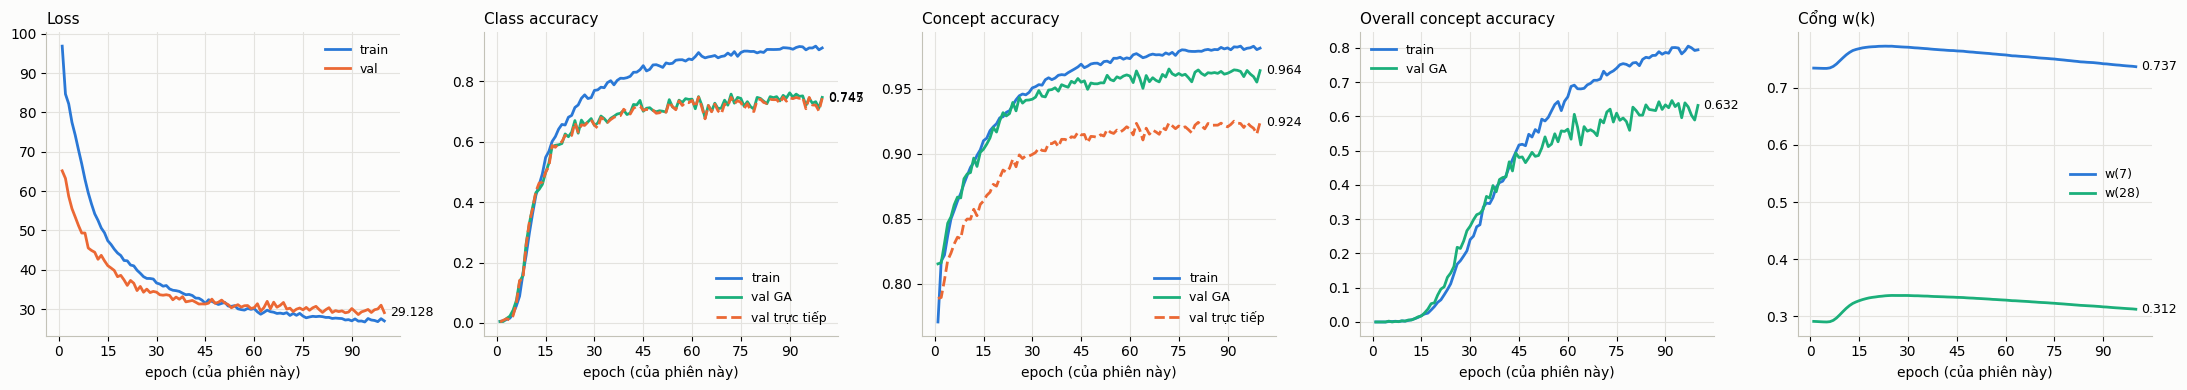

Validation ở epoch cuối: {'accuracy_val_y_xy': 0.7446, 'accuracy_val_c': 0.9243, 'accuracy_val_c_overall': 0.4624, 'accuracy_val_y_post': 0.7471, 'accuracy_val_c_post': 0.964, 'accuracy_val_c_overall_post': 0.6319, 'epoch_val_loss': 29.1279, 'epoch_val_loss_xy': 1.1895, 'epoch_val_loss_xc': 27.715, 'epoch_val_loss_cy': 0.2234, 'epoch_val_loss_joint': 1.8013, 'epoch_val_loss_int': 0.4104, 'epoch_val_loss_mono': 0.0002, 'gate_w_7': 0.737, 'gate_w_28': 0.3125}


In [13]:
# ===== 13. Biểu đồ học =====
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

curves = tensorboard_scalars(TRAIN_DIR)
STYLE = {"train": dict(color="#2a78d6", linestyle="-"), "val": dict(color="#eb6834", linestyle="-"),
         "val GA": dict(color="#1baf7a", linestyle="-"), "val trực tiếp": dict(color="#eb6834", linestyle="--")}
PANELS = [
    ("Loss", [("epoch_loss_epoch", "train"), ("epoch_val_loss", "val")]),
    ("Class accuracy", [("accuracy_train_y_post", "train"), ("accuracy_val_y_post", "val GA"),
                        ("accuracy_val_y_xy", "val trực tiếp")]),
    ("Concept accuracy", [("accuracy_train_c_post", "train"), ("accuracy_val_c_post", "val GA"),
                          ("accuracy_val_c", "val trực tiếp")]),
    ("Overall concept accuracy", [("accuracy_train_c_overall_post", "train"), ("accuracy_val_c_overall_post", "val GA")]),
    ("Cổng w(k)", [("gate_w_7", "train"), ("gate_w_28", "val GA")]),
]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                     "font.size": 10})
fig, axes = plt.subplots(1, len(PANELS), figsize=(22, 4))
for ax, (title, series) in zip(axes, PANELS):
    for tag, label in series:
        values = curves.get(tag, [])
        if not values:
            continue
        shown = "w(7)" if tag == "gate_w_7" else "w(28)" if tag == "gate_w_28" else label
        ax.plot(range(1, len(values) + 1), values, linewidth=2, label=shown, **STYLE[label])
        if label != "train" or title.startswith("Cổng"):
            ax.annotate(f"{values[-1]:.3f}", (len(values), values[-1]), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("epoch (của phiên này)")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "learning_curves.png", dpi=130)
plt.show()
print("Validation ở epoch cuối:", {tag: round(values[-1], 4) for tag, values in curves.items()
                                   if tag.startswith(("accuracy_val", "epoch_val_loss", "gate"))})

## 14. Cách chấm chung cho GA-ECBM và ECBM gốc

- **Ảnh:** loader validation/test của tác giả (cắt giữa 299, không tăng cường).
- **GA-ECBM (D):** tính E_class, E_concept một lần cho mỗi ảnh, rồi dùng công thức đóng. Khi can thiệp, các concept của nhóm đã xác minh được gán giá trị thật, nhánh ảnh nhân w(k).
- **ECBM gốc (A0):** đúng vòng lặp `GradientInference.run_optim` của tác giả (Adam lr 0.1 trên c_prob, y_prob, dừng theo E_class), trọng số 1 : 1 : 0.01. Can thiệp như mã gốc: vòng 2 gán logit (one-hot − 0.5)·10 cho concept đã xác minh, đặt lại y, trọng số 0 : 0 : 3. Backbone chạy một lần để lấy đặc trưng, nhanh hơn script gốc (chạy lại backbone ở mỗi bước) nhưng cho cùng phép tính.
- **Can thiệp:** ở mỗi tỉ lệ 0%, 10%, …, 100% trong 28 nhóm, lấy 5 tập nhóm ngẫu nhiên (cố định, dùng chung cho cả hai mô hình).
- **Chỉ số:** class accuracy; concept accuracy; overall concept accuracy (đúng cả 112); concept accuracy của concept chưa xác minh; tỉ lệ gây hại (ca đang đúng thành sai sau can thiệp); diện tích dưới đường class accuracy theo tỉ lệ can thiệp (AUC can thiệp).

In [14]:
# ===== 14. Cách chấm chung =====
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from argparse import Namespace
from data.cub import load_cub_data
from networks.EBM import ECBM
from utils import EarlyStopping

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_CLASSES, N_CONCEPTS, N_GROUPS = 200, 112, len(GROUPS)
GROUP_OF = torch.zeros(N_CONCEPTS, dtype=torch.long)
for g, indices in enumerate(GROUPS):
    GROUP_OF[indices] = g
AUTHOR_ARGS = Namespace(cy_perturb_prob=0.2, cy_permute_prob=0.2, freezebb=True)


def eval_loader(data_dir, split):
    # Giống get_dataset của tác giả cho val/test: CenterCrop 299, chuẩn hoá (0.5, 2), không lấy mẫu lại.
    return load_cub_data([str(Path(data_dir) / f"{split}.pkl")], use_attr=True, no_img=False, batch_size=64,
                         uncertain_label=False, image_dir=str(data_dir), resol=299,
                         normalizer=T.Normalize(mean=[0.5, 0.5, 0.5], std=[2, 2, 2]), n_classes=N_CLASSES,
                         resampling=False)


def lightning_state(path):
    state = torch.load(path, map_location="cpu", weights_only=False)["state_dict"]
    return {k[len("network."):]: v for k, v in state.items() if k.startswith("network.")}


def load_ga(path):
    model = GAECBM(AUTHOR_ARGS, emb_size=2048, cpt_size=N_CONCEPTS, hid_size=512, n_classes=N_CLASSES)
    model.load_state_dict(lightning_state(path))
    return model.to(DEVICE).eval()


def load_author(path):
    # Như ECBM.load_dict của tác giả: lấy khóa 'network.', bỏ c_prob / y_prob (biến suy luận).
    model = ECBM(AUTHOR_ARGS, emb_size=2048, cpt_size=N_CONCEPTS, hid_size=512, n_classes=N_CLASSES)
    weights = {k: v for k, v in lightning_state(path).items() if "c_prob" not in k and "y_prob" not in k}
    missing, unexpected = model.load_state_dict(weights, strict=False)
    assert not unexpected and set(missing) <= {"energy_model.c_prob", "energy_model.y_prob"}, (missing, unexpected)
    return model.to(DEVICE).eval()


@torch.no_grad()
def run_backbone(model, loader, head=None):
    """Đặc trưng backbone (A0) hoặc năng lượng E_class, E_concept (GA-ECBM) cho cả tập, cùng nhãn và concept."""
    outs, labels, concepts = [], [], []
    for images, y, c in loader:
        images = images.to(DEVICE)
        outs.append(model.energies(images) if head == "ga" else (model.backbone(images),))
        labels.append(torch.as_tensor(y)); concepts.append(c.long())
    merged = tuple(torch.cat([o[i].float().cpu() for o in outs]) for i in range(len(outs[0])))
    return merged, torch.cat(labels), torch.cat(concepts)


# ---------- GA-ECBM ----------
@torch.no_grad()
def predict_ga(model, energies, mask=None, values=None, groups_count=0):
    e_class_all, e_concept_all = energies
    probs_y, probs_c = [], []
    for start in range(0, len(e_class_all), 256):
        e_class, e_concept = e_class_all[start:start + 256].to(DEVICE), e_concept_all[start:start + 256].to(DEVICE)
        if mask is None:
            log_p_y, p_c = model.posterior(e_class, e_concept)
        else:
            weight = model.gate(torch.full((len(e_class),), groups_count, device=DEVICE, dtype=torch.long))
            log_p_y, p_c = model.posterior(e_class, e_concept, mask[start:start + 256].to(DEVICE),
                                           values[start:start + 256].to(DEVICE), weight)
        probs_y.append(log_p_y.exp().cpu()); probs_c.append(p_c.cpu())
    return torch.cat(probs_y), torch.cat(probs_c)


# ---------- ECBM gốc ----------
def author_run_optim(head, features, lambdas, concept_logits=None):
    # Chép GradientInference.run_optim: Adam lr 0.1 trên c_prob / y_prob, dừng theo E_class trung bình của batch.
    count = len(features)
    head.c_prob = nn.Parameter(torch.zeros(count, N_CONCEPTS, 2, device=DEVICE) if concept_logits is None
                               else concept_logits.clone())
    head.y_prob = nn.Parameter(torch.zeros(count, N_CLASSES, 1, device=DEVICE))
    optimizer = torch.optim.Adam([{"params": [head.c_prob], "lr": 0.1}, {"params": [head.y_prob], "lr": 0.1}])
    stop = EarlyStopping(patience=10)
    lambda_xy, lambda_xc, lambda_cy = lambdas
    steps = 0
    with torch.enable_grad():
        while True:
            head.eval()
            optimizer.zero_grad()
            xy_en, cy_en, c_en, _ = head(features, None, False, use_cy=True)
            cpt_loss = sum(c_en[:, i, :].mean() for i in range(c_en.shape[1]))
            loss = lambda_xy * xy_en.mean() + lambda_xc * cpt_loss + lambda_cy * cy_en.mean()
            stop(xy_en.mean().detach(), None)
            loss.backward()
            optimizer.step()
            steps += 1
            if stop.early_stop or steps >= 10000:
                break
    return (F.softmax(head.y_prob.detach(), dim=-2)[:, :, 0], F.softmax(head.c_prob.detach(), dim=-1)[:, :, 1],
            head.c_prob.detach().clone(), steps)


def predict_author(head, features, mask=None, values=None, first_round=None):
    head.requires_grad_(False)
    probs_y, probs_c, rounds, steps = [], [], [], []
    for b, start in enumerate(range(0, len(features), 64)):
        chunk = features[start:start + 64].to(DEVICE)
        if mask is None:
            y, c, logits, n = author_run_optim(head, chunk, (1.0, 1.0, 0.01))
            rounds.append(logits)
        else:
            logits = first_round[b].clone()
            m = mask[start:start + 64].to(DEVICE)
            target = (F.one_hot(values[start:start + 64].to(DEVICE).long(), 2).float() - 0.5) * 10
            logits[m] = target[m]
            y, c, _, n = author_run_optim(head, chunk, (0.0, 0.0, 3.0), concept_logits=logits)
        probs_y.append(y.cpu()); probs_c.append(c.cpu()); steps.append(n)
    return torch.cat(probs_y), torch.cat(probs_c), rounds, steps


# ---------- Chấm ----------
def intervention_plan(seed=2024):
    rng = random.Random(seed)
    plan = []
    for ratio in INTERVENTION_RATIOS:
        count = int(round(ratio * N_GROUPS))
        repeats = 1 if count in (0, N_GROUPS) else INTERVENTION_REPEATS
        plan += [(ratio, sorted(rng.sample(range(N_GROUPS), count))) for _ in range(repeats)]
    return plan


PLAN = intervention_plan()


def summarize(probs_y, probs_c, labels, concepts, mask=None):
    pred_y = probs_y.argmax(1)
    correct_c = (probs_c > 0.5).long() == concepts
    out = {"class_accuracy": float((pred_y == labels).float().mean()),
           "concept_accuracy": float(correct_c.float().mean()),
           "overall_concept_accuracy": float(correct_c.all(1).float().mean())}
    if mask is not None and (~mask).any():
        out["unverified_concept_accuracy"] = float(correct_c[~mask].float().mean())
    return out, pred_y


def evaluate(kind, model, data):
    """kind = 'ga' (data = năng lượng) hoặc 'author' (data = đặc trưng backbone)."""
    inputs, labels, concepts = data
    started = time.time()
    if kind == "author":
        probs_y, probs_c, rounds, steps = predict_author(model, inputs[0])
    else:
        probs_y, probs_c = predict_ga(model, inputs)
        rounds, steps = None, None
    base, base_pred = summarize(probs_y, probs_c, labels, concepts)
    base_correct = base_pred == labels
    curve = []
    for ratio, groups in PLAN:
        if not groups:
            curve.append({"ratio": ratio, **base, "harm_rate": 0.0, "help_rate": 0.0})
            continue
        concept_mask = torch.isin(GROUP_OF, torch.tensor(groups))
        mask = concept_mask.expand(len(labels), -1)
        if kind == "author":
            probs_y_i, probs_c_i, _, _ = predict_author(model, inputs[0], mask, concepts, rounds)
        else:
            probs_y_i, probs_c_i = predict_ga(model, inputs, mask, concepts, len(groups))
        stats, pred = summarize(probs_y_i, probs_c_i, labels, concepts, mask)
        stats["harm_rate"] = float((base_correct & (pred != labels)).float().mean())
        stats["help_rate"] = float((~base_correct & (pred == labels)).float().mean())
        curve.append({"ratio": ratio, **stats})
    by_ratio = {}
    for row in curve:
        by_ratio.setdefault(row["ratio"], []).append(row)
    mean_curve = [{"ratio": r, **{key: float(np.mean([row[key] for row in rows if key in row]))
                                  for key in rows[-1] if key != "ratio"}} for r, rows in by_ratio.items()]
    ratios = [row["ratio"] for row in mean_curve]
    integrate = getattr(np, "trapezoid", None) or np.trapz
    auc = float(integrate([row["class_accuracy"] for row in mean_curve], ratios) / (ratios[-1] - ratios[0]))
    return {"unintervened": base, "curve": mean_curve, "intervention_auc": auc,
            "inference_steps": None if steps is None else {"min": min(steps), "max": max(steps),
                                                            "mean": float(np.mean(steps))},
            "seconds": time.time() - started}


def find_author_checkpoint():
    # last.ckpt của bản tái lập ECBM gốc trong Input (log.txt không có dòng GA-ECBM)
    ga = set(ga_checkpoints(INPUT))
    found = [p for p in (INPUT.rglob("exp/*/last.ckpt") if INPUT.exists() else []) if p not in ga]
    return sorted(found, key=lambda p: p.stat().st_mtime)[-1] if found else None


A0_CKPT = find_author_checkpoint()
if A0_CKPT is not None:
    assert f"random_seed={SEED}" in (A0_CKPT.parent / "log.txt").read_text(errors="replace"), \
        f"Checkpoint ECBM ở Input không phải seed {SEED}: {A0_CKPT}. Chỉ gắn notebook ecbm-cub-seed{SEED}."
print(f"{N_GROUPS} nhóm; {len(PLAN)} tập nhóm can thiệp dùng chung | checkpoint ECBM gốc: {A0_CKPT or 'không có'}")

# Chấm thử checkpoint của mục 11 trên 64 ảnh validation, rồi xoá
smoke_val = run_backbone(load_ga(SMOKE_DIR / "last.ckpt"), eval_loader(CUB_SMOKE, "val"), head="ga")
smoke_result = evaluate("ga", load_ga(SMOKE_DIR / "last.ckpt"), smoke_val)
print("Chấm thử GA-ECBM:", {k: round(v, 4) for k, v in smoke_result["unintervened"].items()},
      "| AUC can thiệp", round(smoke_result["intervention_auc"], 4))
if A0_CKPT is not None:
    a0_smoke = load_author(A0_CKPT)
    smoke_feat = run_backbone(a0_smoke, eval_loader(CUB_SMOKE, "val"))
    smoke_a0 = evaluate("author", a0_smoke.energy_model, (smoke_feat[0], smoke_feat[1], smoke_feat[2]))
    print("Chấm thử ECBM gốc:", {k: round(v, 4) for k, v in smoke_a0["unintervened"].items()},
          "| bước suy luận", smoke_a0["inference_steps"])
    del a0_smoke
shutil.rmtree(SMOKE_DIR)
if torch.cuda.is_available():
    torch.cuda.empty_cache()

28 nhóm; 47 tập nhóm can thiệp dùng chung | checkpoint ECBM gốc: /kaggle/input/notebooks/ntkngulu/ecbm-cub-seed2026/ECBM/exp/2026-11-13_10-04-55/last.ckpt
Chấm thử GA-ECBM: {'class_accuracy': 0.0, 'concept_accuracy': 0.5095, 'overall_concept_accuracy': 0.0} | AUC can thiệp 0.0055
Chấm thử ECBM gốc: {'class_accuracy': 0.7344, 'concept_accuracy': 0.9597, 'overall_concept_accuracy': 0.4844} | bước suy luận {'min': 36, 'max': 36, 'mean': 36.0}


## 15. Chấm GA-ECBM

Dùng `last.ckpt` (như README của tác giả và như lần tái lập). Chấm validation; chấm test chỉ khi `EVALUATE_TEST = True`.

In [15]:
# ===== 15. Chấm GA-ECBM =====
SPLITS_TO_SCORE = ["val"] + (["test"] if EVALUATE_TEST else [])
ga_model = load_ga(GA_CKPT)
w = ga_model.gate(torch.arange(N_GROUPS + 1, device=DEVICE)).detach().cpu().numpy()
print("Cổng sau train: w(0) = 1, w(7) = %.3f, w(14) = %.3f, w(28) = %.3f" % (w[7], w[14], w[28]))
RESULTS = {"gate": w.tolist()}
for split in SPLITS_TO_SCORE:
    data = run_backbone(ga_model, eval_loader(CUB_FULL, split), head="ga")
    direct = {"class_accuracy": float((data[0][0].argmin(1) == data[1]).float().mean()),
              "concept_accuracy": float((data[0][1].argmin(2) == data[2]).float().mean())}
    RESULTS[f"D_{split}"] = evaluate("ga", ga_model, data)
    RESULTS[f"D_{split}"]["direct_energy"] = direct
    u = RESULTS[f"D_{split}"]["unintervened"]
    print(f"GA-ECBM {split}: class {u['class_accuracy']:.4f} | concept {u['concept_accuracy']:.4f} | overall "
          f"{u['overall_concept_accuracy']:.4f} | AUC can thiệp {RESULTS[f'D_{split}']['intervention_auc']:.4f} "
          f"| đọc trực tiếp năng lượng: {direct}")
(OUT / "results.json").write_text(json.dumps(RESULTS, indent=2))
del ga_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Cổng sau train: w(0) = 1, w(7) = 0.736, w(14) = 0.563, w(28) = 0.312
GA-ECBM val: class 0.7471 | concept 0.9640 | overall 0.6319 | AUC can thiệp 0.8790 | đọc trực tiếp năng lượng: {'class_accuracy': 0.7454090118408203, 'concept_accuracy': 0.9628994464874268}
GA-ECBM test: class 0.7615 | concept 0.9655 | overall 0.6540 | AUC can thiệp 0.8885 | đọc trực tiếp năng lượng: {'class_accuracy': 0.7545737028121948, 'concept_accuracy': 0.9639713764190674}


## 16. Chấm ECBM gốc (bản tái lập) bằng cùng cách chấm

Cần đã gắn Output của `ECBM_CUB` ở Input. Nếu có chấm test, số của ECBM gốc ở đây phải gần số tái lập trước đó (0.955 / 0.543 / 0.711); đó là phép kiểm tra rằng vòng lặp suy luận chép lại đúng.

In [16]:
# ===== 16. Chấm ECBM gốc =====
if A0_CKPT is None:
    print("Không có checkpoint ECBM gốc trong Input: bỏ qua so sánh. Add Input → Your Work → ECBM_CUB.")
else:
    a0_model = load_author(A0_CKPT)
    for split in SPLITS_TO_SCORE:
        feats = run_backbone(a0_model, eval_loader(CUB_FULL, split))
        RESULTS[f"A0_{split}"] = evaluate("author", a0_model.energy_model, feats)
        u = RESULTS[f"A0_{split}"]["unintervened"]
        print(f"ECBM gốc {split}: class {u['class_accuracy']:.4f} | concept {u['concept_accuracy']:.4f} | overall "
              f"{u['overall_concept_accuracy']:.4f} | AUC can thiệp {RESULTS[f'A0_{split}']['intervention_auc']:.4f} "
              f"| bước suy luận {RESULTS[f'A0_{split}']['inference_steps']} | {RESULTS[f'A0_{split}']['seconds'] / 60:.1f} phút")
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2))
    del a0_model

ECBM gốc val: class 0.7371 | concept 0.9610 | overall 0.5710 | AUC can thiệp 0.8541 | bước suy luận {'min': 36, 'max': 38, 'mean': 36.21052631578947} | 29.2 phút
ECBM gốc test: class 0.7601 | concept 0.9640 | overall 0.5977 | AUC can thiệp 0.8584 | bước suy luận {'min': 34, 'max': 45, 'mean': 38.56043956043956} | 146.3 phút


## 17. So sánh và kết luận theo tiêu chí đã chốt

Tiêu chí (chốt trước, trên validation, ghi ở `plan.json`): GA-ECBM so với ECBM gốc
- AUC can thiệp tăng **≥ 2 điểm**;
- khi chưa can thiệp: class accuracy giảm ≤ 0.5 điểm, concept accuracy giảm ≤ 0.2 điểm, overall concept accuracy giảm ≤ 1 điểm.

Chỉ có **1 seed** cho mỗi mô hình (như lần tái lập), nên kết luận ở đây là tín hiệu, chưa đủ để khẳng định.

           Mô hình  Tập  Class acc  Concept acc  Overall concept acc  AUC can thiệp  Class acc khi xác minh 50% nhóm  Gây hại TB
ECBM gốc (tái lập)  val     0.7371       0.9610               0.5710         0.8541                           0.8703      0.0253
ECBM gốc (tái lập) test     0.7601       0.9640               0.5977         0.8584                           0.8702      0.0280
           GA-ECBM  val     0.7471       0.9640               0.6319         0.8790                           0.8910      0.0000
           GA-ECBM test     0.7615       0.9655               0.6540         0.8885                           0.8997      0.0002

Tiêu chí (validation):
  ✓ AUC can thiệp tăng ≥ 2 điểm
  ✓ class acc giảm ≤ 0.5 điểm
  ✓ concept acc giảm ≤ 0.2 điểm
  ✓ overall concept acc giảm ≤ 1 điểm
  ΔAUC can thiệp = +0.0248 | Δ chưa can thiệp: Class acc +0.0100, Concept acc +0.0030, Overall concept acc +0.0609 → ĐẠT (1 seed)


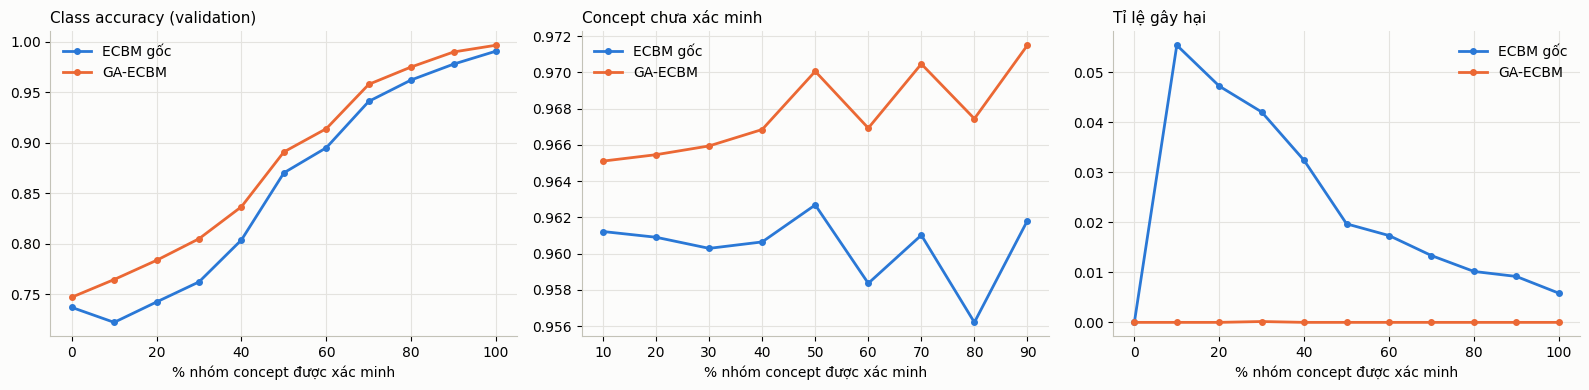


Đã lưu /kaggle/working/ga_ecbm_cub_results/summary.json
Các file trong Output: ['comparison.csv', 'intervention_curves.png', 'learning_curves.png', 'patches.diff', 'plan.json', 'results.json', 'smoke_train.log', 'state.json', 'summary.json']


In [17]:
# ===== 17. So sánh và kết luận =====
import pandas as pd

LABELS = {"class_accuracy": "Class acc", "concept_accuracy": "Concept acc", "overall_concept_accuracy": "Overall concept acc"}
rows = []
for key, label in (("A0", "ECBM gốc (tái lập)"), ("D", "GA-ECBM")):
    for split in SPLITS_TO_SCORE:
        if f"{key}_{split}" in RESULTS:
            r = RESULTS[f"{key}_{split}"]
            row = {"Mô hình": label, "Tập": split}
            row.update({LABELS[k]: round(r["unintervened"][k], 4) for k in LABELS})
            row["AUC can thiệp"] = round(r["intervention_auc"], 4)
            row["Class acc khi xác minh 50% nhóm"] = round(next(c["class_accuracy"] for c in r["curve"] if c["ratio"] == 0.5), 4)
            row["Gây hại TB"] = round(float(np.mean([c["harm_rate"] for c in r["curve"] if c["ratio"] > 0])), 4)
            rows.append(row)
table = pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv(OUT / "comparison.csv", index=False)

VERDICT = None
if "A0_val" in RESULTS:
    a, d = RESULTS["A0_val"], RESULTS["D_val"]
    drop = {k: a["unintervened"][k] - d["unintervened"][k] for k in LABELS}
    checks = {
        "AUC can thiệp tăng ≥ 2 điểm": d["intervention_auc"] - a["intervention_auc"] >= CRITERIA["auc_gain"],
        "class acc giảm ≤ 0.5 điểm": drop["class_accuracy"] <= CRITERIA["max_class_drop"],
        "concept acc giảm ≤ 0.2 điểm": drop["concept_accuracy"] <= CRITERIA["max_concept_drop"],
        "overall concept acc giảm ≤ 1 điểm": drop["overall_concept_accuracy"] <= CRITERIA["max_overall_concept_drop"],
    }
    checks = {name: bool(ok) for name, ok in checks.items()}
    VERDICT = "ĐẠT (1 seed)" if all(checks.values()) else "KHÔNG ĐẠT"
    print("\nTiêu chí (validation):")
    for name, ok in checks.items():
        print(("  ✓ " if ok else "  ✗ ") + name)
    print(f"  ΔAUC can thiệp = {d['intervention_auc'] - a['intervention_auc']:+.4f} | Δ chưa can thiệp: "
          + ", ".join(f"{LABELS[k]} {-v:+.4f}" for k, v in drop.items()) + f" → {VERDICT}")

# Đường can thiệp
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
COLORS = {"A0": "#2a78d6", "D": "#eb6834"}
for key, label in (("A0", "ECBM gốc"), ("D", "GA-ECBM")):
    if f"{key}_val" not in RESULTS:
        continue
    curve = RESULTS[f"{key}_val"]["curve"]
    x = [c["ratio"] * 100 for c in curve]
    for ax, metric in zip(axes, ("class_accuracy", "unverified_concept_accuracy", "harm_rate")):
        y = [c.get(metric, np.nan) for c in curve]
        ax.plot(x, y, marker="o", markersize=4, linewidth=2, color=COLORS[key], label=label)
for ax, title in zip(axes, ("Class accuracy (validation)", "Concept chưa xác minh", "Tỉ lệ gây hại")):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("% nhóm concept được xác minh")
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "intervention_curves.png", dpi=130)
plt.show()

state = load_state()
summary = {
    "goal": "GA-ECBM (Gated Additive ECBM) end-to-end trên CUB, cùng code và công thức train với bản tái lập ECBM gốc",
    "code": {"repo": OFFICIAL_REPO, "commit": OFFICIAL_COMMIT, "patches_and_new_files": "patches.diff"},
    "epochs": EPOCHS, "seeds": 1, "seed": SEED, "gate_init": GATE_INIT, "train_overrides": state.get("train_overrides"),
    "resumed_from": state.get("resumed_from"), "checkpoint": str(GA_CKPT), "author_checkpoint": str(A0_CKPT),
    "results": RESULTS, "verdict_val": VERDICT, "criteria": CRITERIA, "test_evaluated": EVALUATE_TEST,
    "paper_ecbm_test": PAPER_ECBM, "reproduced_ecbm_test": REPRODUCED_TEST,
    "time": {"train_hours": state.get("train_hours"), "notebook_hours": (time.time() - NOTEBOOK_START) / 3600},
    "versions": state.get("versions"), "benchmark": state.get("bench"),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nĐã lưu", OUT / "summary.json")
print("Các file trong Output:", sorted(path.name for path in OUT.iterdir()))

## Đọc kết quả

- **Số chính** ở mục 17: so GA-ECBM với ECBM gốc trên validation, cùng cách chấm, cùng các tập nhóm can thiệp.
- **AUC can thiệp** đo việc sửa concept có kéo class accuracy lên hay không. ECBM gốc ở vòng 2 chỉ dùng E_global; GA-ECBM điều kiện hoá chính xác và giảm dần trọng số ảnh theo w(k).
- **Tập test:** đổi `EVALUATE_TEST = True` ở mục 1 rồi chạy lại (Input là Output của lần này để khỏi train lại: mục 12 sẽ dùng luôn `last.ckpt`).
- **Output:** `ga_ecbm_cub_results/` (summary.json, comparison.csv, results.json, các hình, log, patches.diff); `ECBM/exp/<thời điểm>/` chứa checkpoint (khoảng 360 MB mỗi file).